# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

### **Họ tên:** Phạm Ngọc Minh

### **MSSV:** 24521082

### **Lớp:** DS201.R12

#### Mục tiêu

- Hiểu cách CNN xử lý ảnh qua các lớp tích chập, pooling và phân loại
- Xây dựng và huấn luyện LeNet-5, GoogLeNet rút gọn, ResNet-18 và ResNet-50 pretrained bằng PyTorch
- So sánh ảnh hưởng của pooling, data augmentation và transfer learning
- Đánh giá mô hình trên VinaFood21 bằng accuracy, precision, recall và macro-F1

#### Yêu cầu

Dùng bộ dữ liệu **VinaFood21 gồm 21 lớp**. Giữ nguyên tập test; tách validation từ tập train với seed cố định. Chỉ áp dụng data augmentation cho tập train. Các thí nghiệm dùng cùng một phép chia dữ liệu để có thể so sánh kết quả.

1. **Bài 1 — LeNet-5:** Huấn luyện trên ảnh RGB 64×64 bằng Adam. Chạy hai phiên bản AvgPool và MaxPool, rồi so sánh macro-F1.
2. **Bài 2 — GoogLeNet rút gọn:** Xây dựng mạng gồm 3–4 Inception block trên ảnh 64×64. Dùng global average pooling trước lớp phân loại; so sánh số tham số, thời gian mỗi epoch và macro-F1 với LeNet-5.
3. **Bài 3 — ResNet-18:** Xây dựng ResNet-18 đầy đủ `[2, 2, 2, 2]`, huấn luyện từ đầu trên ảnh 96×96 hoặc 112×112. Chạy hai lần có và không có augmentation; so sánh macro-F1 và đường loss.
4. **Bài 4 — ResNet-50 pretrained:** Sử dụng `microsoft/resnet-50` từ Hugging Face trên ảnh 224×224. Chạy cả feature extraction và fine-tuning, rồi so sánh với ResNet-18 huấn luyện từ đầu.

Với mỗi thí nghiệm, báo cáo **số tham số, accuracy, precision-macro, recall-macro, macro-F1, F1 từng lớp và confusion matrix 21×21** trên tập test. Chọn checkpoint bằng kết quả validation; chỉ đánh giá test sau khi đã chọn mô hình. Cuối bài, lập bảng so sánh các mô hình và nhận xét dựa trên kết quả thực tế.

**Nộp bài:** Push notebook chứa code và kết quả lên GitHub. Tạo file `<MSSV>.txt` chứa đường dẫn repository và nộp file này trên Courses.

## 1. Chuẩn bị dữ liệu

In [17]:
from pathlib import Path
roots = [
    p.parent for p in Path("/kaggle/input").rglob("train")
    if (p.parent / "test").is_dir()
]
assert len(roots) == 1, f"Kiểm tra các thư mục dữ liệu tìm thấy: {roots}"
DATA_ROOT = roots[0]
print("DATA_ROOT:", DATA_ROOT)

DATA_ROOT: /kaggle/input/datasets/choiupe/vinafood21/VinaFood21


## 2. Import thư viện và cấu hình

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split

SEED = 42
IMG_SIZE = 64
BATCH_SIZE = 32
NUM_WORKERS = 2
VAL_RATIO = 0.10

RUN_EXPERIMENTS = True
SKIP_COMPLETED = True
EPOCHS_BASIC = 20
EPOCHS_ADVANCED = 20
EPOCHS_TRANSFER = 20

OUT_ROOT = Path("/kaggle/working/output_lab2")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

torch.manual_seed(SEED)
def n_params(module, trainable_only=False):
    parameters = module.parameters()
    if trainable_only:
        parameters = (p for p in parameters if p.requires_grad)
    return sum(p.numel() for p in parameters)

DATA_READY = (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "test").is_dir()
print("Có dữ liệu:", DATA_READY)
print("Device:", device)

Có dữ liệu: True
Device: cuda


## 3. Pipeline dữ liệu dùng chung

In [19]:
def build_transforms(img_size, augment=True):
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


def make_loaders(img_size, augment=True):
    train_tf, eval_tf = build_transforms(img_size, augment)
    full_train = datasets.ImageFolder(DATA_ROOT / 'train', transform=train_tf)
    test_ds = datasets.ImageFolder(DATA_ROOT / 'test', transform=eval_tf)

    if (DATA_ROOT / 'val').is_dir():
        train_ds = full_train
        val_ds = datasets.ImageFolder(DATA_ROOT / 'val', transform=eval_tf)
        val_classes = val_ds.class_to_idx
    else:
        n_val = int(len(full_train) * VAL_RATIO)
        train_part, val_part = random_split(
            full_train, [len(full_train) - n_val, n_val],
            generator=torch.Generator().manual_seed(SEED)
        )
        val_images = datasets.ImageFolder(DATA_ROOT / 'train', transform=eval_tf)
        train_ds = train_part
        val_ds = Subset(val_images, val_part.indices)
        val_classes = val_images.class_to_idx

    if len(full_train.classes) != 21:
        raise ValueError(f'Cần 21 lớp, đang có {len(full_train.classes)}.')
    if full_train.class_to_idx != val_classes:
        raise ValueError('Nhãn lớp train/validation không khớp.')
    if full_train.class_to_idx != test_ds.class_to_idx:
        raise ValueError('Nhãn lớp train/test không khớp.')

    common = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    train_dl = DataLoader(train_ds, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), **common)
    val_dl = DataLoader(val_ds, shuffle=False, **common)
    test_dl = DataLoader(test_ds, shuffle=False, **common)
    return train_dl, val_dl, test_dl, full_train.classes

In [20]:
def dataset_targets(ds):
    if isinstance(ds, Subset):
        return [ds.dataset.targets[i] for i in ds.indices]
    return ds.targets

In [21]:
train_dl, val_dl, test_dl, CLASSES = make_loaders(64, augment=True)

print("Số lớp:", len(CLASSES))
print("Số ảnh train/val/test:",
      len(train_dl.dataset),
      len(val_dl.dataset),
      len(test_dl.dataset))
print("Một số tên lớp:", CLASSES[:5])

image, label = train_dl.dataset[0]
xb, yb = next(iter(train_dl))

print("Một ảnh:", tuple(image.shape))   
print("Một batch:", tuple(xb.shape))    
print("Nhãn:", tuple(yb.shape))         
assert len(CLASSES) == 21
assert xb.shape[1:] == (3, 64, 64)

Số lớp: 21
Số ảnh train/val/test: 9040 1004 6682
Một số tên lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron']
Một ảnh: (3, 64, 64)
Một batch: (32, 3, 64, 64)
Nhãn: (32,)


## 4. Khung huấn luyện và đánh giá

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred


def four_metrics(y_true, y_pred, num_classes=21):
    labels = list(range(num_classes))
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0),
        'recall_macro': recall_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0),
        'macro_f1': f1_score(
            y_true, y_pred, labels=labels, average='macro', zero_division=0),
    }

### Lưu kết quả của một thí nghiệm

In [23]:
import time
import seaborn as sns
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix

def run_experiment(name, model_factory, img_size, augment, lr, epochs):
    torch.manual_seed(SEED)
    train_dl, val_dl, test_dl, classes = make_loaders(img_size, augment)
    folder = OUT_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)

    model = model_factory().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        (p for p in model.parameters() if p.requires_grad), lr=lr)
    print(name, '| số tham số:', n_params(model),
          '| tham số học:', n_params(model, trainable_only=True))

    history = []
    best_f1, best_epoch = -1.0, 0
    for ep in range(1, epochs + 1):
        if device.type == 'cuda':
            torch.cuda.synchronize()  # Để đo đúng thời gian trên GPU
        start = time.perf_counter()

        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, truth, pred = evaluate(model, val_dl, criterion, device)
        va_f1 = f1_score(truth, pred, labels=list(range(len(classes))),
                         average='macro', zero_division=0)

        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        history.append({'epoch': ep, 'train_loss': tr_loss, 'val_loss': va_loss,
                        'train_acc': tr_acc, 'val_acc': va_acc,
                        'val_macro_f1': va_f1, 'seconds': seconds})

        if va_f1 > best_f1:
            best_f1, best_epoch = va_f1, ep
            torch.save(model.state_dict(), folder / 'best.pt')
        print(f'{name} | epoch {ep:02d}/{epochs} | '
              f'train loss {tr_loss:.4f}, acc {tr_acc:.4f} | '
              f'val loss {va_loss:.4f}, acc {va_acc:.4f}, macro-F1 {va_f1:.4f}')

    history_df = pd.DataFrame(history)
    history_df.to_csv(folder / 'history.csv', index=False)
    plt.figure(figsize=(8, 5))
    plt.plot(history_df['epoch'], history_df['train_loss'], label='train loss')
    plt.plot(history_df['epoch'], history_df['val_loss'], label='val loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title(name); plt.legend()
    plt.tight_layout(); plt.savefig(folder / 'loss_curve.png'); plt.show()

    model.load_state_dict(torch.load(folder / 'best.pt', map_location=device,
                                     weights_only=True))
    test_loss, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    labels = list(range(len(classes)))
    metrics = four_metrics(y_true, y_pred, len(classes))
    report = classification_report(y_true, y_pred, labels=labels,
                                   target_names=classes, digits=4, zero_division=0)
    report_dict = classification_report(y_true, y_pred, labels=labels,
                                        target_names=classes, output_dict=True,
                                        zero_division=0)
    print('Kết quả test:\n', report)
    (folder / 'classification_report.txt').write_text(report, encoding='utf-8')
    per_class = pd.DataFrame(report_dict).T.loc[
        classes, ['precision', 'recall', 'f1-score', 'support']]
    display(per_class)
    per_class.to_csv(folder / 'per_class_metrics.csv', encoding='utf-8-sig')

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(
        folder / 'confusion_matrix.csv', encoding='utf-8-sig')
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm, cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Nhãn dự đoán'); plt.ylabel('Nhãn thật')
    plt.title(f'{name}: confusion matrix trên test')
    plt.xticks(rotation=90); plt.tight_layout()
    plt.savefig(folder / 'confusion_matrix.png'); plt.show()

    metrics.update(name=name, img_size=img_size, parameters=n_params(model),
                   trainable_parameters=n_params(model, trainable_only=True),
                   seconds_per_epoch=history_df['seconds'].mean(),
                   best_epoch=best_epoch, best_val_macro_f1=best_f1,
                   epochs=epochs, test_loss=test_loss,
                   n_train=len(train_dl.dataset), n_val=len(val_dl.dataset))
    pd.DataFrame([metrics]).to_csv(folder / 'metrics.csv', index=False)
    display(pd.DataFrame([metrics]).round(4))
    return metrics

## 5. Bài 1 — LeNet-5

In [24]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool='avg'):
        super().__init__()
        if pool not in ('avg', 'max'):
            raise ValueError('pool phải là avg hoặc max')
        Pool = nn.AvgPool2d if pool == 'avg' else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
            self.n_flat = z.flatten(1).shape[1]
        self.f5 = nn.Linear(self.n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

def lenet_avg():
    return LeNet5(pool='avg')

def lenet_max():
    return LeNet5(pool='max')

def lenet_layer_table(model):
    x, rows = torch.zeros(1, 3, 64, 64), []
    for name in ['c1', 's2', 'c3', 's4']:
        layer = getattr(model, name)
        x = layer(x)
        rows.append({'layer': name, 'output': str(tuple(x.shape)), 'parameters': n_params(layer)})
    x = x.flatten(1)
    for name in ['f5', 'f6', 'out']:
        layer = getattr(model, name)
        x = layer(x)
        rows.append({'layer': name, 'output': str(tuple(x.shape)), 'parameters': n_params(layer)})
    return pd.DataFrame(rows)

avg | flatten: 2704 | parameters: 339421 | logits: (2, 21)
max | flatten: 2704 | parameters: 339421 | logits: (2, 21)


,layer,output,parameters
0,c1,"(1, 6, 60, 60)",456
1,s2,"(1, 6, 30, 30)",0
2,c3,"(1, 16, 26, 26)",2416
3,s4,"(1, 16, 13, 13)",0
4,f5,"(1, 120)",324600
5,f6,"(1, 84)",10164
6,out,"(1, 21)",1785


lenet_avg | số tham số: 339421 | tham số học: 339421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_avg | epoch 01/20 | train loss 2.8263, acc 0.1415 | val loss 2.7579, acc 0.1584, macro-F1 0.0685


...

lenet_avg | epoch 18/20 | train loss 1.8985, acc 0.4087 | val loss 2.1773, acc 0.3476, macro-F1 0.3120


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_avg | epoch 19/20 | train loss 1.8742, acc 0.4190 | val loss 2.1188, acc 0.3466, macro-F1 0.3261


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_avg | epoch 20/20 | train loss 1.8650, acc 0.4183 | val loss 2.1378, acc 0.3446, macro-F1 0.3217


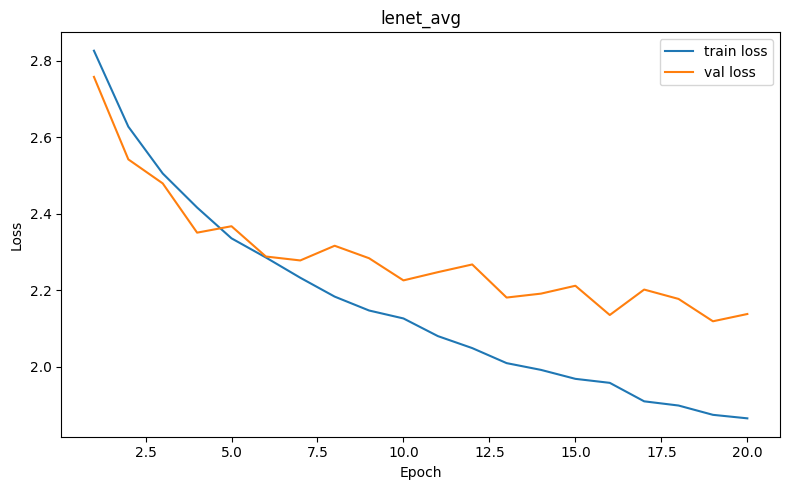

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.2137    0.2075    0.2105       241
        banh-hoi     0.3228    0.4053    0.3594       607
    banh-mi-chao     0.3122    0.3910    0.3472       289
        banh-tet     0.3122    0.1758    0.2250       364
 banh-trang-tron     0.2065    0.1230    0.1542       309
          banh-u     0.3000    0.1023    0.1525       176
        banh-uot     0.2589    0.3643    0.3027       560
       bap-nuong     0.1711    0.0909    0.1187       143
          bo-kho     0.3141    0.3550    0.3333       338
       bo-la-lot     0.3971    0.6070    0.4801       458
       bot-chien     0.1726    0.3007    0.2193       276
           ca-ri     0.1926    0.1520    0.1699       171
    canh-kho-qua     0.4467    0.4483    0.4475       290
   canh-khoai-mo     0.7249    0.6919    0.7080       198
        ga-nuong     0.2800    0.1505    0.1958       372
          goi-ga     0.2077    0.2414    0.2233       29

,precision,recall,f1-score,support
banh-can,0.213675,0.207469,0.210526,241.0
banh-hoi,0.322835,0.405272,0.359386,607.0
banh-mi-chao,0.312155,0.391003,0.347158,289.0
banh-tet,0.312195,0.175824,0.224956,364.0
banh-trang-tron,0.206522,0.122977,0.154158,309.0
banh-u,0.300000,0.102273,0.152542,176.0
banh-uot,0.258883,0.364286,0.302671,560.0
bap-nuong,0.171053,0.090909,0.118721,143.0
bo-kho,0.314136,0.355030,0.333333,338.0
bo-la-lot,0.397143,0.606987,0.480138,458.0


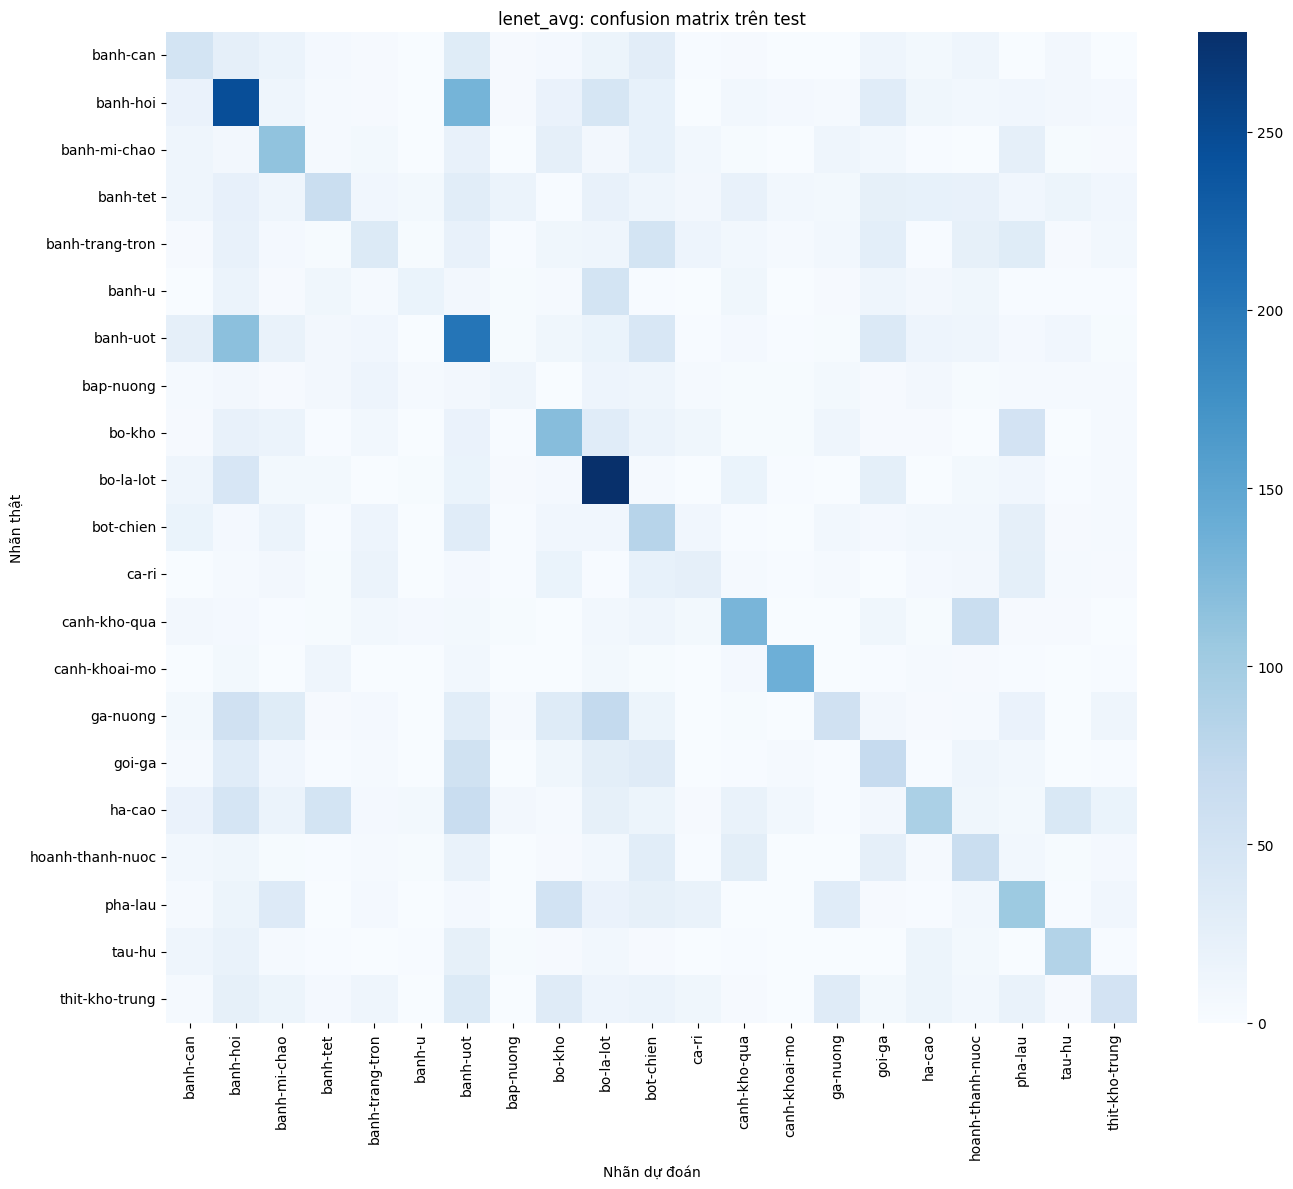

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.306,0.3064,0.2926,0.2883,lenet_avg,64,339421,339421,116.1329,19,0.3261,20,2.3089,9040,1004


lenet_max | số tham số: 339421 | tham số học: 339421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_max | epoch 01/20 | train loss 2.7942, acc 0.1483 | val loss 2.6352, acc 0.1912, macro-F1 0.1367


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

lenet_max | epoch 18/20 | train loss 1.8199, acc 0.4322 | val loss 2.1196, acc 0.3645, macro-F1 0.3522


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_max | epoch 19/20 | train loss 1.7947, acc 0.4419 | val loss 2.0444, acc 0.3934, macro-F1 0.3774


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_max | epoch 20/20 | train loss 1.7861, acc 0.4471 | val loss 2.0790, acc 0.3805, macro-F1 0.3627


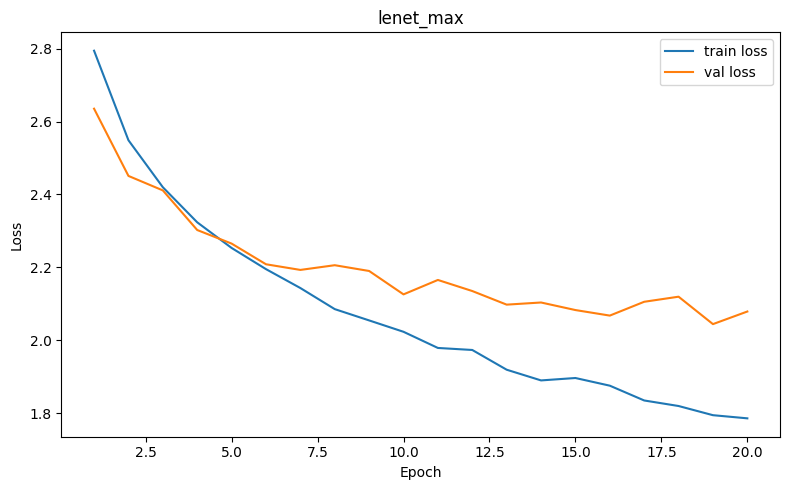

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.1905    0.1660    0.1774       241
        banh-hoi     0.3668    0.4514    0.4047       607
    banh-mi-chao     0.3404    0.3356    0.3380       289
        banh-tet     0.3814    0.3049    0.3389       364
 banh-trang-tron     0.2268    0.1424    0.1750       309
          banh-u     0.3068    0.1534    0.2045       176
        banh-uot     0.2802    0.3107    0.2947       560
       bap-nuong     0.1562    0.1049    0.1255       143
          bo-kho     0.3405    0.3728    0.3559       338
       bo-la-lot     0.4592    0.5895    0.5163       458
       bot-chien     0.1699    0.3442    0.2275       276
           ca-ri     0.2279    0.1813    0.2020       171
    canh-kho-qua     0.4570    0.5310    0.4912       290
   canh-khoai-mo     0.7869    0.7273    0.7559       198
        ga-nuong     0.3350    0.1801    0.2343       372
          goi-ga     0.3094    0.1483    0.2005       29

,precision,recall,f1-score,support
banh-can,0.190476,0.165975,0.177384,241.0
banh-hoi,0.366801,0.451400,0.404727,607.0
banh-mi-chao,0.340351,0.335640,0.337979,289.0
banh-tet,0.381443,0.304945,0.338931,364.0
banh-trang-tron,0.226804,0.142395,0.174950,309.0
banh-u,0.306818,0.153409,0.204545,176.0
banh-uot,0.280193,0.310714,0.294666,560.0
bap-nuong,0.156250,0.104895,0.125523,143.0
bo-kho,0.340541,0.372781,0.355932,338.0
bo-la-lot,0.459184,0.589520,0.516252,458.0


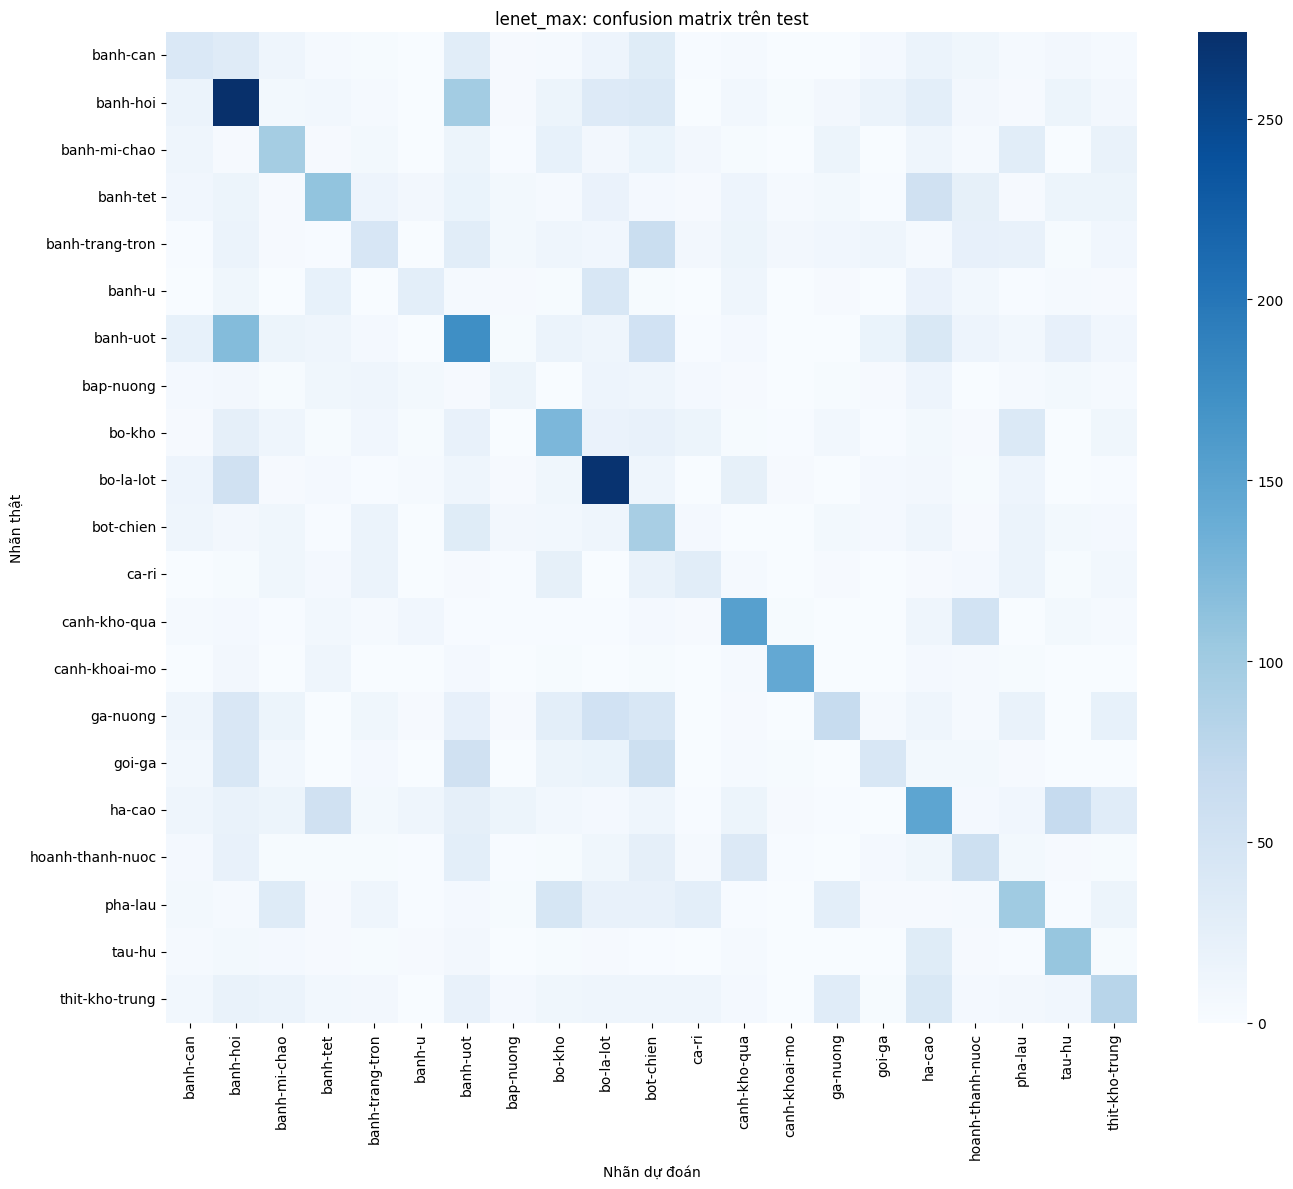

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.3304,0.3259,0.3172,0.3137,lenet_max,64,339421,339421,101.3819,19,0.3774,20,2.2347,9040,1004


In [25]:
for pool in ('avg', 'max'):
    m = LeNet5(pool=pool).eval()
    with torch.no_grad():
        y = m(torch.randn(2, 3, 64, 64))
    assert m.n_flat == 2704 and n_params(m) == 339421 and y.shape == (2, 21)
    print(pool, '| flatten:', m.n_flat, '| parameters:', n_params(m), '| logits:', tuple(y.shape))
display(lenet_layer_table(LeNet5()))
del m

RESULTS = {}
if RUN_EXPERIMENTS:
    RESULTS['lenet_avg'] = run_experiment('lenet_avg', lenet_avg, 64, True, 1e-3, EPOCHS_BASIC)
    RESULTS['lenet_max'] = run_experiment('lenet_max', lenet_max, 64, True, 1e-3, EPOCHS_BASIC)

## 6. Bài 2 — GoogLeNet rút gọn 3 Inception block

In [26]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
                                nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
                                nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),
                                nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class SmallGoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU())
        self.block1 = InceptionBlock(16, 16, 16, 24, 4, 8, 8)
        self.block2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
        self.block3 = InceptionBlock(112, 64, 64, 96, 16, 32, 32)
        self.down = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(224, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.down(self.block1(x))
        x = self.down(self.block2(x))
        x = self.block3(x)
        return self.fc(self.gap(x).flatten(1))

,block,channel_tính_tay,shape_code,parameters
0,block1,56,"(2, 56, 64, 64)",5036
1,block2,112,"(2, 112, 32, 32)",22104
2,block3,224,"(2, 224, 16, 16)",88112


Tổng tham số GoogLeNet rút gọn: 120425
googlenet | số tham số: 120425 | tham số học: 120425


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


googlenet | epoch 01/20 | train loss 2.8762, acc 0.1249 | val loss 2.7456, acc 0.1594, macro-F1 0.0633


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

googlenet | epoch 18/20 | train loss 1.8202, acc 0.4369 | val loss 1.8365, acc 0.4373, macro-F1 0.4078


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


googlenet | epoch 19/20 | train loss 1.7965, acc 0.4338 | val loss 1.7906, acc 0.4512, macro-F1 0.4270


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


googlenet | epoch 20/20 | train loss 1.7817, acc 0.4434 | val loss 1.8592, acc 0.4283, macro-F1 0.3955


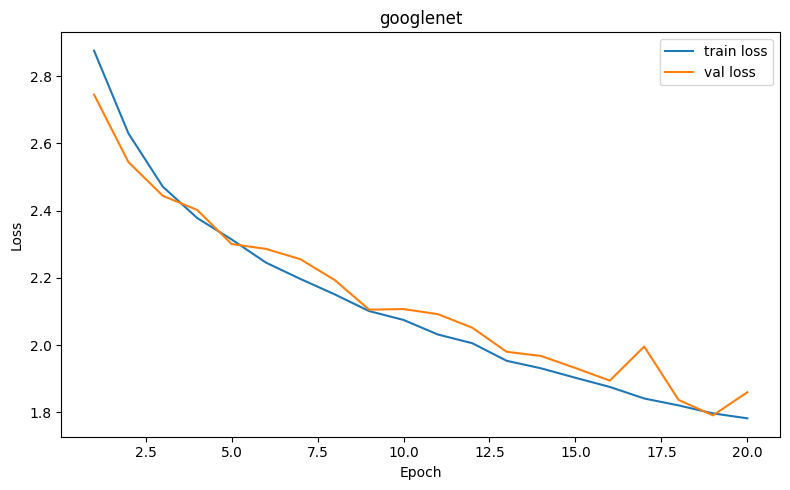

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.2412    0.2573    0.2490       241
        banh-hoi     0.5217    0.5750    0.5470       607
    banh-mi-chao     0.4613    0.4325    0.4464       289
        banh-tet     0.3973    0.4038    0.4005       364
 banh-trang-tron     0.3333    0.2265    0.2697       309
          banh-u     0.4000    0.2159    0.2804       176
        banh-uot     0.3693    0.4214    0.3937       560
       bap-nuong     0.2542    0.1049    0.1485       143
          bo-kho     0.3566    0.5148    0.4213       338
       bo-la-lot     0.4566    0.7009    0.5530       458
       bot-chien     0.1376    0.2174    0.1685       276
           ca-ri     0.2661    0.1930    0.2237       171
    canh-kho-qua     0.4937    0.5379    0.5149       290
   canh-khoai-mo     0.8581    0.6414    0.7341       198
        ga-nuong     0.4379    0.1801    0.2552       372
          goi-ga     0.3913    0.2793    0.3260       29

,precision,recall,f1-score,support
banh-can,0.241245,0.257261,0.248996,241.0
banh-hoi,0.521674,0.574959,0.547022,607.0
banh-mi-chao,0.461255,0.432526,0.446429,289.0
banh-tet,0.397297,0.403846,0.400545,364.0
banh-trang-tron,0.333333,0.226537,0.269750,309.0
banh-u,0.400000,0.215909,0.280443,176.0
banh-uot,0.369327,0.421429,0.393661,560.0
bap-nuong,0.254237,0.104895,0.148515,143.0
bo-kho,0.356557,0.514793,0.421308,338.0
bo-la-lot,0.456615,0.700873,0.552972,458.0


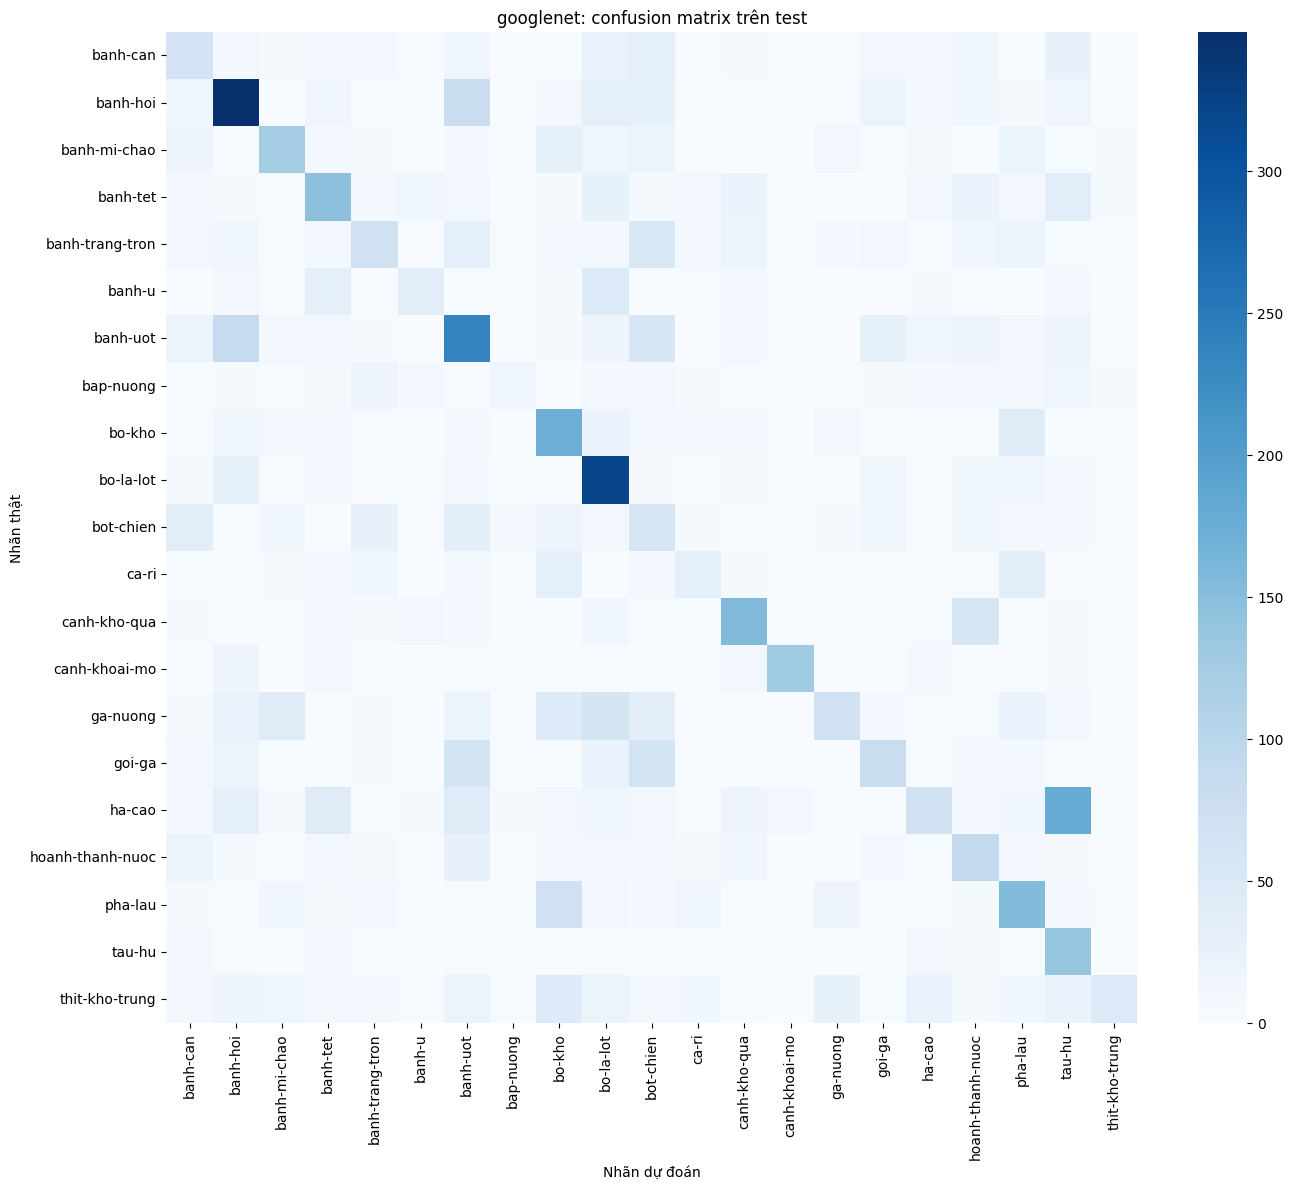

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.3831,0.3917,0.3661,0.3561,googlenet,64,120425,120425,101.9458,19,0.427,20,2.0196,9040,1004


In [27]:
assert n_params(InceptionBlock(1, 16, 16, 24, 4, 8, 8)) == 4376
assert n_params(InceptionBlock(56, 32, 32, 48, 8, 16, 16)) == 22104
g = SmallGoogLeNet().eval()
with torch.no_grad():
    x = g.stem(torch.rand(2, 3, 64, 64))
    rows = []
    for i, (name, expected) in enumerate([('block1', 56), ('block2', 112), ('block3', 224)]):
        layer = getattr(g, name)
        x = layer(x)
        rows.append({'block': name, 'channel_tính_tay': expected, 'shape_code': str(tuple(x.shape)),
                     'parameters': n_params(layer)})
        assert x.shape[1] == expected
        if i < 2:
            x = g.down(x)
    assert g(torch.rand(2, 3, 64, 64)).shape == (2, 21)
display(pd.DataFrame(rows))
print('Tổng tham số GoogLeNet rút gọn:', n_params(g))
del g
if RUN_EXPERIMENTS:
    RESULTS['googlenet'] = run_experiment('googlenet', SmallGoogLeNet, 64, True, 1e-3, EPOCHS_BASIC)

## 7. Bài 3* — ResNet-18 từ đầu, có và không augmentation

In [28]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                                          nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))

class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
                                  nn.BatchNorm2d(64), nn.ReLU(),
                                  nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, 1)
        self.layer2 = self._stage(64, 128, 2)
        self.layer3 = self._stage(128, 256, 2)
        self.layer4 = self._stage(256, 512, 2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))

,stage,output,parameters
0,stem,"(2, 64, 24, 24)",9536
1,layer1,"(2, 64, 24, 24)",147968
2,layer2,"(2, 128, 12, 12)",525568
3,layer3,"(2, 256, 6, 6)",2099712
4,layer4,"(2, 512, 3, 3)",8393728


Tổng tham số ResNet-18: 11187285
resnet18_noaug | số tham số: 11187285 | tham số học: 11187285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_noaug | epoch 01/20 | train loss 2.6487, acc 0.1983 | val loss 2.4511, acc 0.2430, macro-F1 0.1839


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

resnet18_noaug | epoch 18/20 | train loss 0.1344, acc 0.9535 | val loss 2.8647, acc 0.4811, macro-F1 0.4745


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_noaug | epoch 19/20 | train loss 0.0680, acc 0.9784 | val loss 2.8054, acc 0.5100, macro-F1 0.5022


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_noaug | epoch 20/20 | train loss 0.0639, acc 0.9784 | val loss 3.0418, acc 0.4701, macro-F1 0.4682


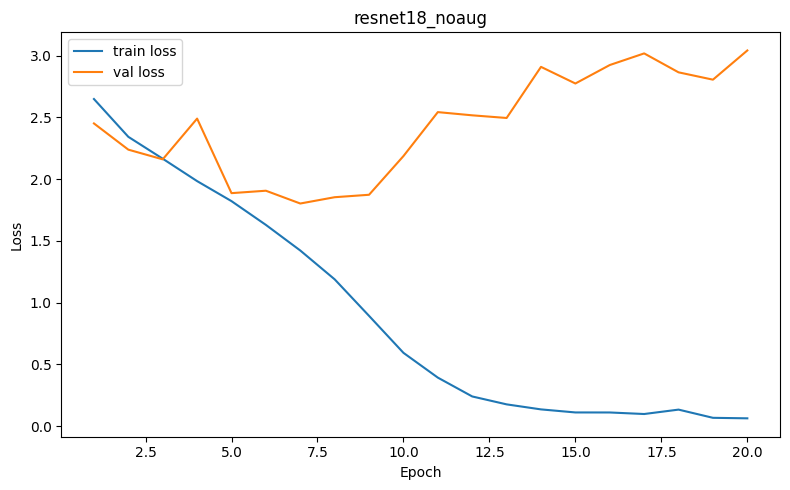

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.2615    0.2822    0.2715       241
        banh-hoi     0.5535    0.4942    0.5222       607
    banh-mi-chao     0.5901    0.3287    0.4222       289
        banh-tet     0.4631    0.4313    0.4467       364
 banh-trang-tron     0.3074    0.2686    0.2867       309
          banh-u     0.3534    0.2670    0.3042       176
        banh-uot     0.3522    0.3786    0.3649       560
       bap-nuong     0.2357    0.2587    0.2467       143
          bo-kho     0.3538    0.4763    0.4061       338
       bo-la-lot     0.5972    0.6572    0.6258       458
       bot-chien     0.4153    0.1775    0.2487       276
           ca-ri     0.2676    0.2222    0.2428       171
    canh-kho-qua     0.5015    0.5759    0.5361       290
   canh-khoai-mo     0.7716    0.7677    0.7696       198
        ga-nuong     0.4346    0.3306    0.3756       372
          goi-ga     0.4000    0.4345    0.4165       29

,precision,recall,f1-score,support
banh-can,0.261538,0.282158,0.271457,241.0
banh-hoi,0.553506,0.494234,0.522193,607.0
banh-mi-chao,0.590062,0.328720,0.422222,289.0
banh-tet,0.463127,0.431319,0.446657,364.0
banh-trang-tron,0.307407,0.268608,0.286701,309.0
banh-u,0.353383,0.267045,0.304207,176.0
banh-uot,0.352159,0.378571,0.364888,560.0
bap-nuong,0.235669,0.258741,0.246667,143.0
bo-kho,0.353846,0.476331,0.406053,338.0
bo-la-lot,0.597222,0.657205,0.625780,458.0


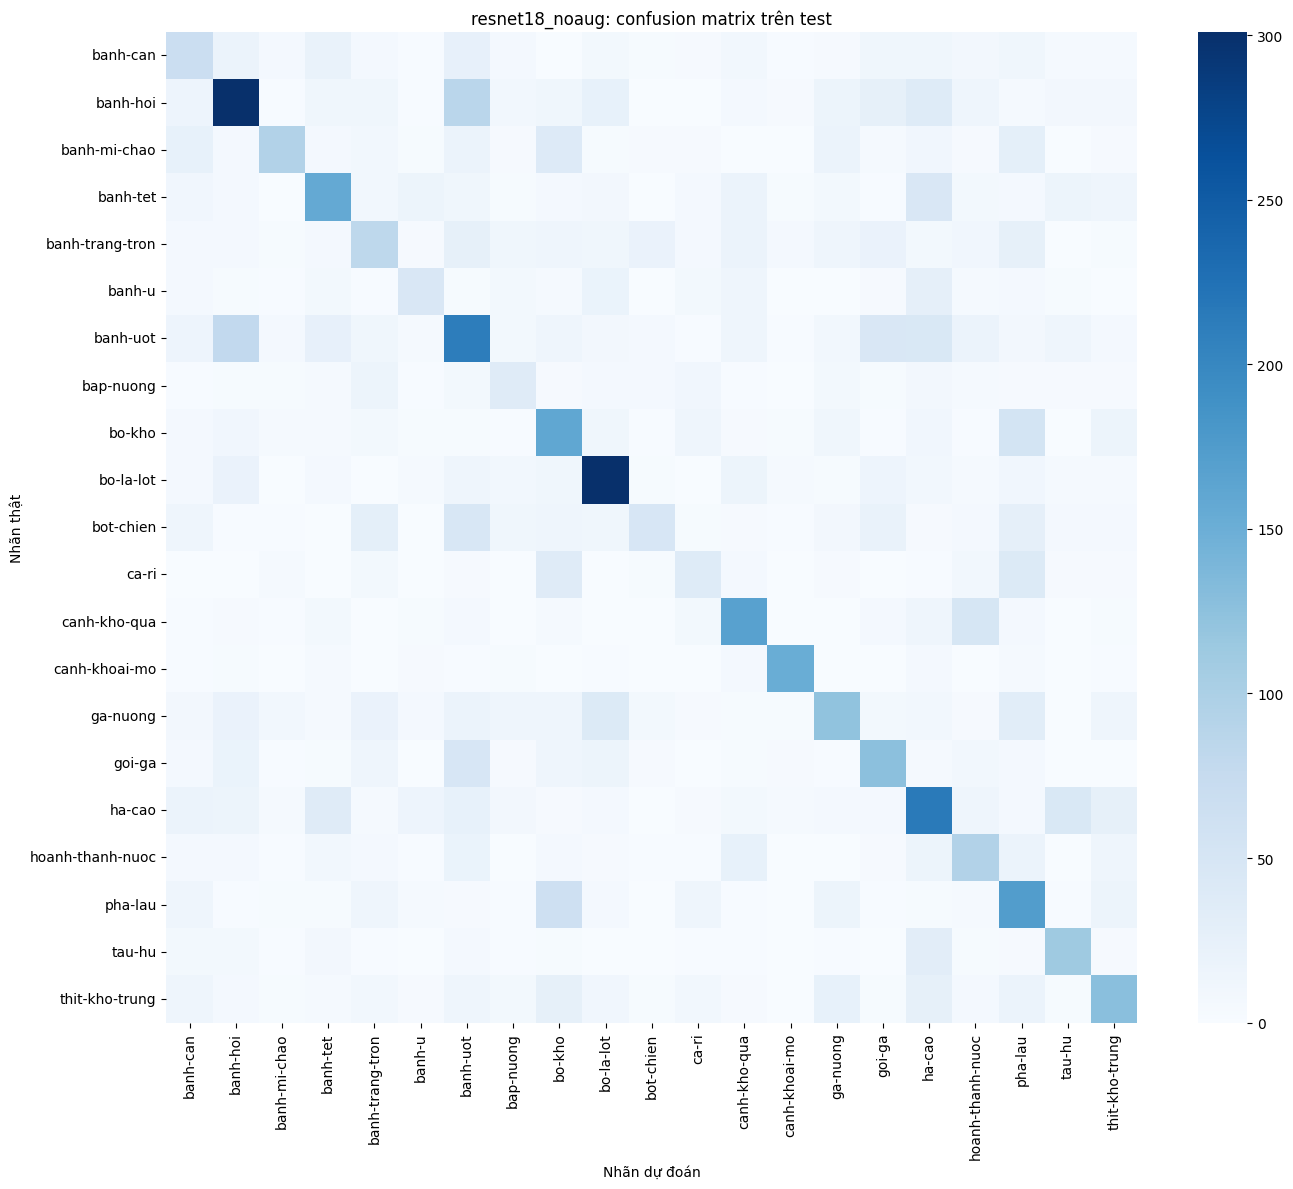

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.4249,0.4208,0.411,0.4092,resnet18_noaug,96,11187285,11187285,90.9962,19,0.5022,20,3.4741,9040,1004


resnet18_aug | số tham số: 11187285 | tham số học: 11187285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_aug | epoch 01/20 | train loss 2.7214, acc 0.1869 | val loss 2.5019, acc 0.2181, macro-F1 0.1771


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

resnet18_aug | epoch 18/20 | train loss 1.1641, acc 0.6229 | val loss 1.4462, acc 0.5528, macro-F1 0.5537


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_aug | epoch 19/20 | train loss 1.1161, acc 0.6390 | val loss 1.3738, acc 0.5657, macro-F1 0.5550


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet18_aug | epoch 20/20 | train loss 1.0653, acc 0.6572 | val loss 1.4399, acc 0.5388, macro-F1 0.5236


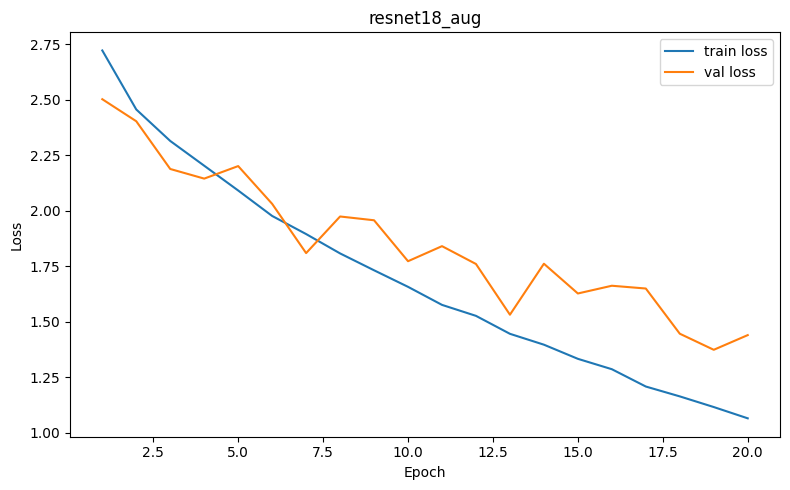

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.4718    0.3817    0.4220       241
        banh-hoi     0.5484    0.5783    0.5630       607
    banh-mi-chao     0.6107    0.5156    0.5591       289
        banh-tet     0.6809    0.4808    0.5636       364
 banh-trang-tron     0.3754    0.3754    0.3754       309
          banh-u     0.4638    0.3636    0.4076       176
        banh-uot     0.4138    0.5446    0.4703       560
       bap-nuong     0.4062    0.2727    0.3264       143
          bo-kho     0.4865    0.4793    0.4829       338
       bo-la-lot     0.5443    0.7642    0.6358       458
       bot-chien     0.4585    0.5000    0.4783       276
           ca-ri     0.3721    0.2807    0.3200       171
    canh-kho-qua     0.6757    0.6034    0.6375       290
   canh-khoai-mo     0.7339    0.8081    0.7692       198
        ga-nuong     0.4507    0.2581    0.3282       372
          goi-ga     0.4127    0.5138    0.4578       29

,precision,recall,f1-score,support
banh-can,0.471795,0.381743,0.422018,241.0
banh-hoi,0.548438,0.578254,0.562951,607.0
banh-mi-chao,0.610656,0.515571,0.559099,289.0
banh-tet,0.680934,0.480769,0.563607,364.0
banh-trang-tron,0.375405,0.375405,0.375405,309.0
banh-u,0.463768,0.363636,0.407643,176.0
banh-uot,0.413840,0.544643,0.470316,560.0
bap-nuong,0.406250,0.272727,0.326360,143.0
bo-kho,0.486486,0.479290,0.482861,338.0
bo-la-lot,0.544323,0.764192,0.635786,458.0


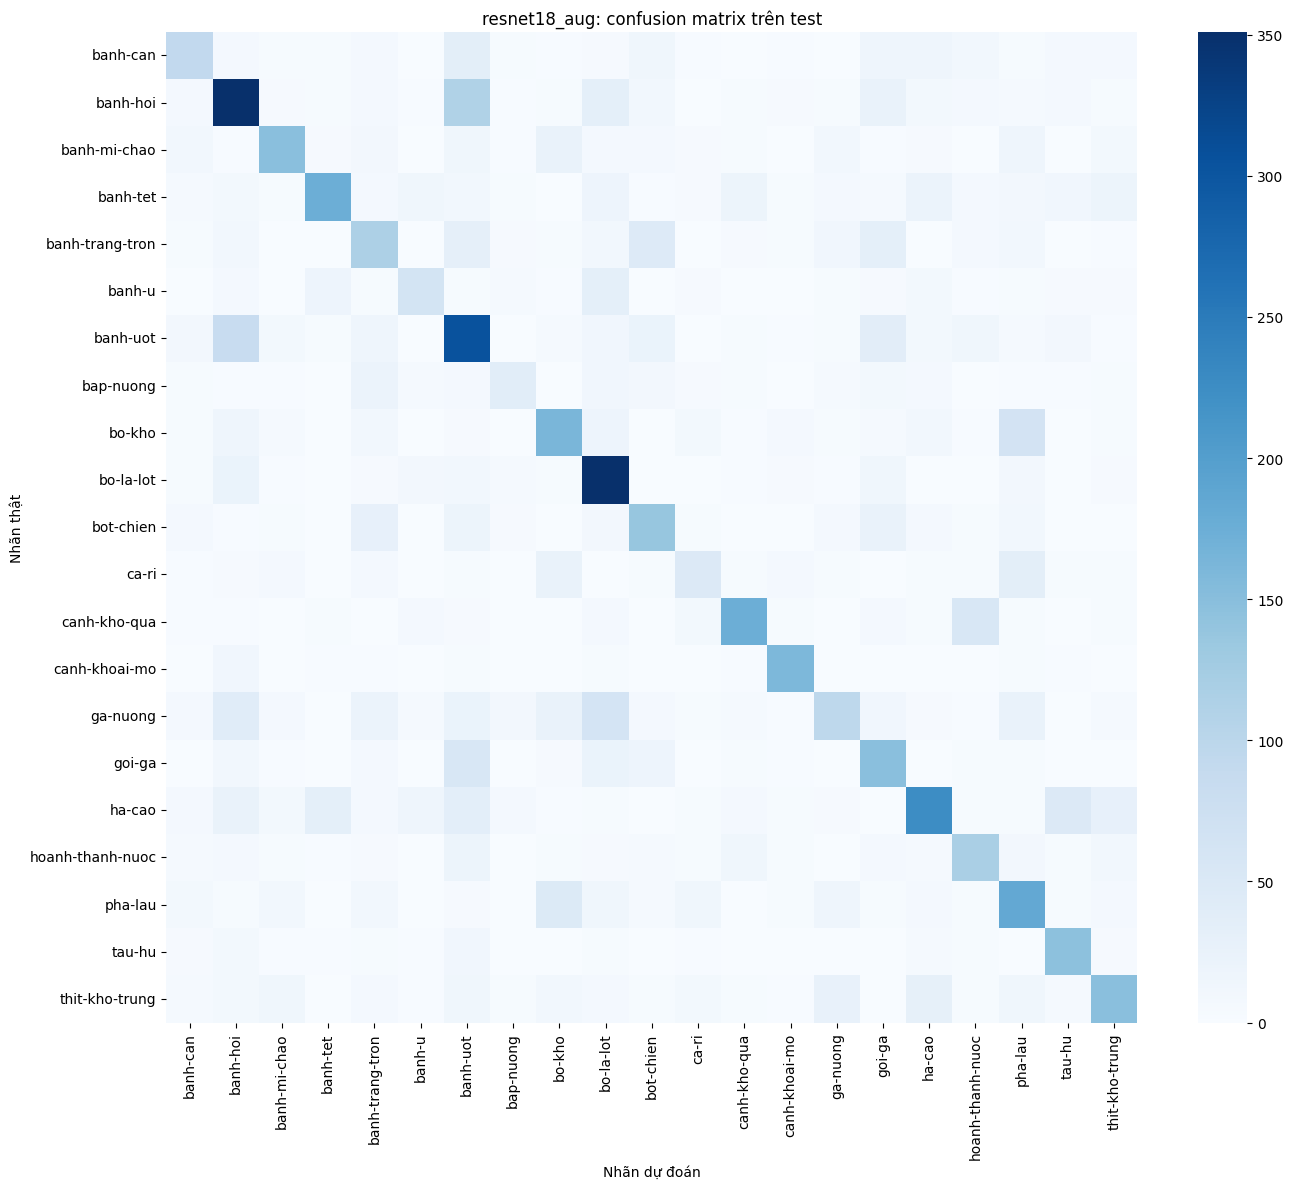

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.5079,0.5088,0.4948,0.4951,resnet18_aug,96,11187285,11187285,109.0984,19,0.555,20,1.6641,9040,1004


In [29]:
assert n_params(BasicBlock(64, 64)) == 73984
r = ResNet18().eval()
assert n_params(r) == 11187285
with torch.no_grad():
    x = r.stem(torch.rand(2, 3, 96, 96))
    rows = [{'stage': 'stem', 'output': str(tuple(x.shape)), 'parameters': n_params(r.stem)}]
    for name in ['layer1', 'layer2', 'layer3', 'layer4']:
        layer = getattr(r, name); x = layer(x)
        rows.append({'stage': name, 'output': str(tuple(x.shape)), 'parameters': n_params(layer)})
    assert x.shape == (2, 512, 3, 3)
    assert r(torch.rand(2, 3, 96, 96)).shape == (2, 21)
display(pd.DataFrame(rows))
print('Tổng tham số ResNet-18:', n_params(r))
del r
if RUN_EXPERIMENTS:
    RESULTS['resnet18_noaug'] = run_experiment('resnet18_noaug', ResNet18, 96, False, 1e-3, EPOCHS_ADVANCED)
    RESULTS['resnet18_aug'] = run_experiment('resnet18_aug', ResNet18, 96, True, 1e-3, EPOCHS_ADVANCED)

## 8. Bài 4* — ResNet-50 pretrained từ Hugging Face

In [30]:
class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        from transformers import ResNetForImageClassification
        base = ResNetForImageClassification.from_pretrained('microsoft/resnet-50')
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes)
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for p in self.resnet.parameters():
                p.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.resnet.eval()  
        return self

    def forward(self, images):
        features = self.resnet(pixel_values=images).pooler_output
        return self.classifier(features.flatten(1))


def resnet50_feature_extraction():
    return PretrainedResnet(freeze_backbone=True)


def resnet50_finetune():
    return PretrainedResnet(freeze_backbone=False)

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

resnet50_fe | số tham số: 23551061 | tham số học: 43029


...

resnet50_fe | epoch 18/20 | train loss 0.5340, acc 0.8447 | val loss 0.6645, acc 0.7769, macro-F1 0.7831


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet50_fe | epoch 19/20 | train loss 0.5216, acc 0.8488 | val loss 0.6468, acc 0.7859, macro-F1 0.7992


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet50_fe | epoch 20/20 | train loss 0.5107, acc 0.8551 | val loss 0.6509, acc 0.7839, macro-F1 0.7977


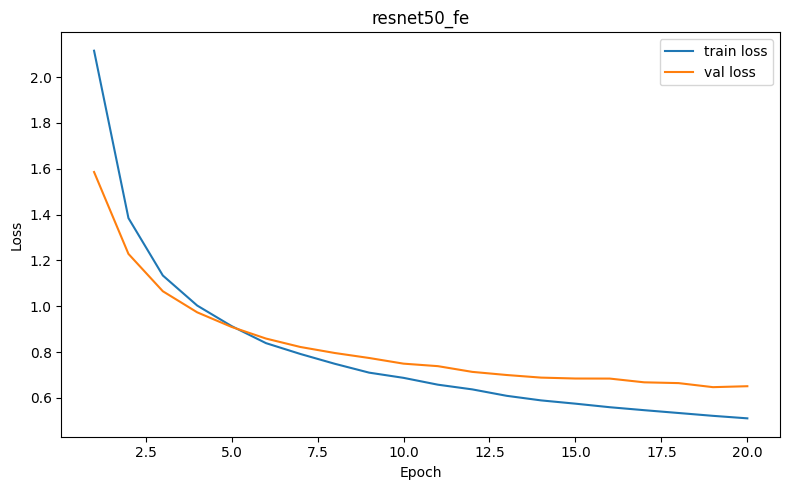

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.7854    0.7593    0.7722       241
        banh-hoi     0.7387    0.6705    0.7029       607
    banh-mi-chao     0.8245    0.8616    0.8426       289
        banh-tet     0.9557    0.7115    0.8157       364
 banh-trang-tron     0.8523    0.7282    0.7853       309
          banh-u     0.7333    0.8750    0.7979       176
        banh-uot     0.5900    0.6500    0.6185       560
       bap-nuong     0.9716    0.9580    0.9648       143
          bo-kho     0.6414    0.7249    0.6806       338
       bo-la-lot     0.7769    0.8515    0.8125       458
       bot-chien     0.7148    0.6630    0.6880       276
           ca-ri     0.4832    0.4211    0.4500       171
    canh-kho-qua     0.8264    0.8207    0.8235       290
   canh-khoai-mo     0.9043    0.8586    0.8808       198
        ga-nuong     0.7716    0.7446    0.7579       372
          goi-ga     0.6803    0.6310    0.6547       29

,precision,recall,f1-score,support
banh-can,0.785408,0.759336,0.772152,241.0
banh-hoi,0.738657,0.670511,0.702936,607.0
banh-mi-chao,0.824503,0.861592,0.842640,289.0
banh-tet,0.955720,0.711538,0.815748,364.0
banh-trang-tron,0.852273,0.728155,0.785340,309.0
banh-u,0.733333,0.875000,0.797927,176.0
banh-uot,0.589951,0.650000,0.618522,560.0
bap-nuong,0.971631,0.958042,0.964789,143.0
bo-kho,0.641361,0.724852,0.680556,338.0
bo-la-lot,0.776892,0.851528,0.812500,458.0


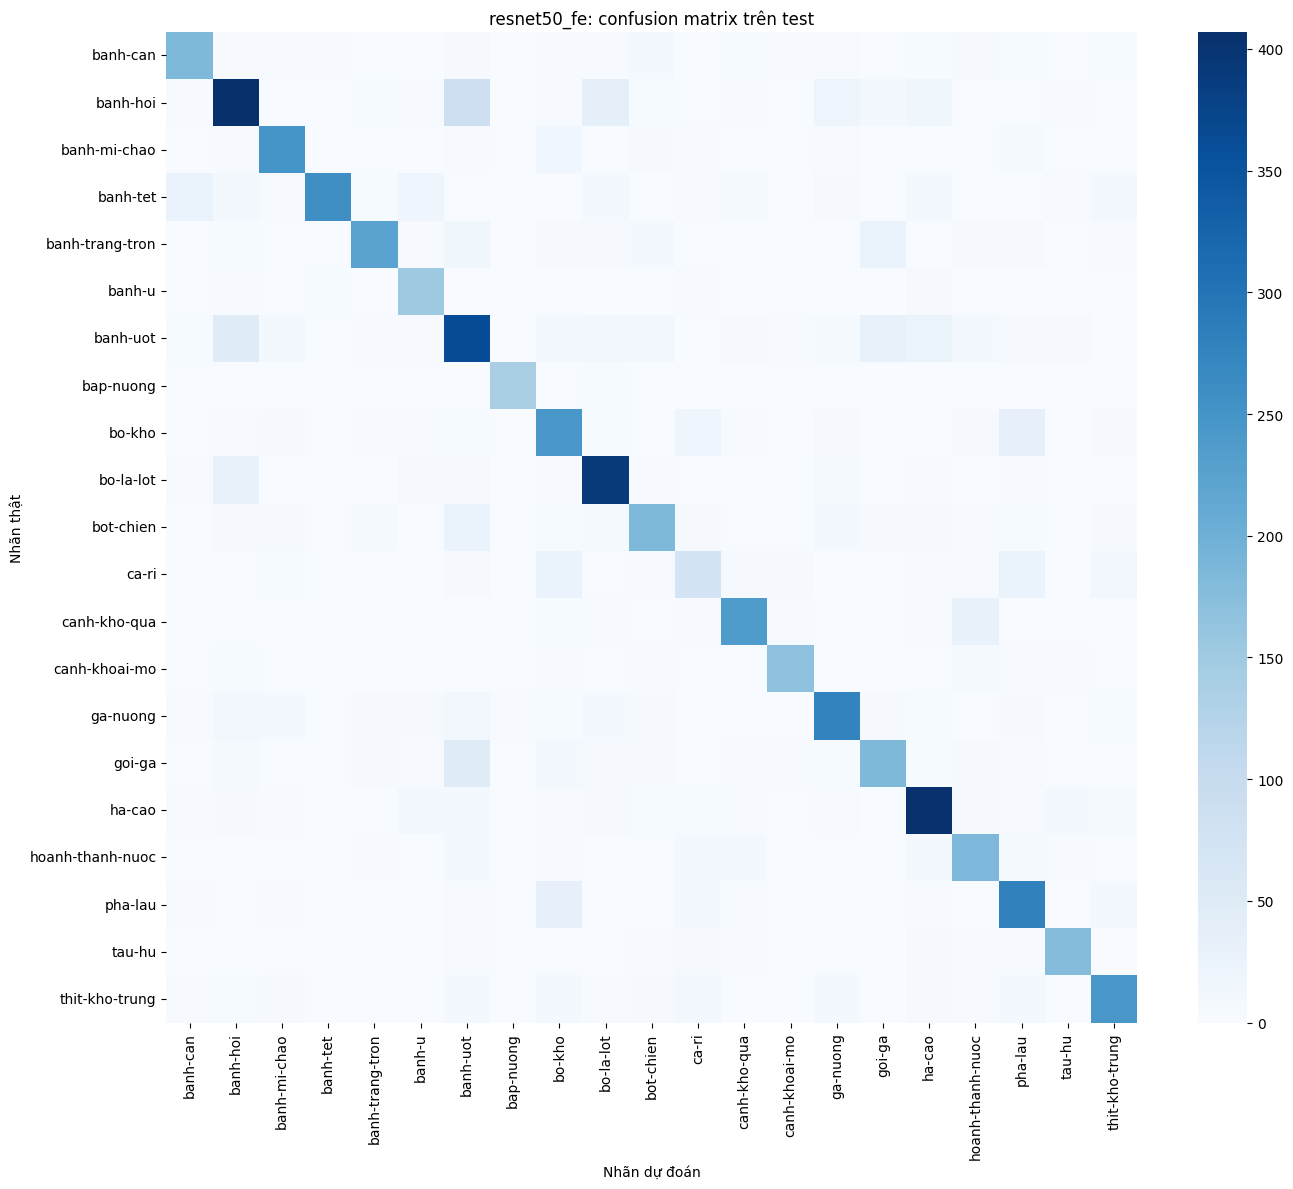

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.7528,0.7656,0.7607,0.7608,resnet50_fe,224,23551061,43029,127.8485,19,0.7992,20,0.7947,9040,1004


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

resnet50_ft | số tham số: 23551061 | tham số học: 23551061


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet50_ft | epoch 01/20 | train loss 2.7375, acc 0.1900 | val loss 2.2395, acc 0.4432, macro-F1 0.3375


...

resnet50_ft | epoch 18/20 | train loss 0.0880, acc 0.9753 | val loss 0.3564, acc 0.8974, macro-F1 0.8987


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet50_ft | epoch 19/20 | train loss 0.0834, acc 0.9741 | val loss 0.3803, acc 0.9004, macro-F1 0.9044


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


resnet50_ft | epoch 20/20 | train loss 0.0729, acc 0.9794 | val loss 0.3751, acc 0.9004, macro-F1 0.9033


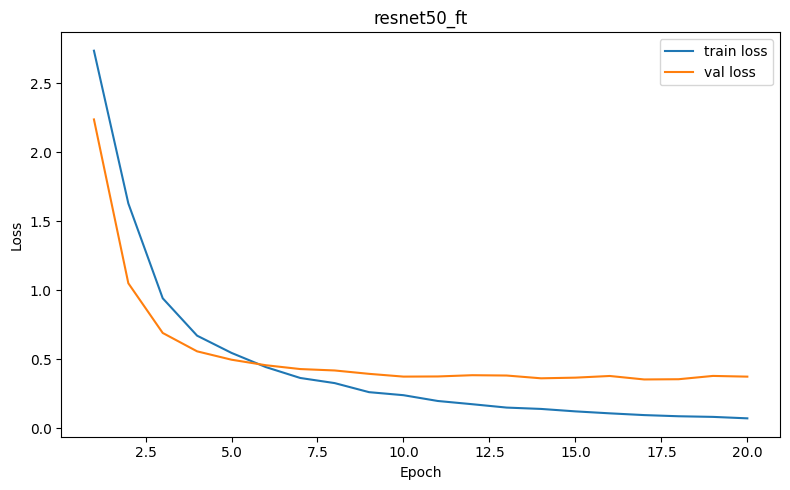

Kết quả test:
                   precision    recall  f1-score   support

        banh-can     0.8296    0.9295    0.8767       241
        banh-hoi     0.8270    0.8979    0.8610       607
    banh-mi-chao     0.9073    0.9481    0.9272       289
        banh-tet     0.9650    0.8324    0.8938       364
 banh-trang-tron     0.9343    0.8285    0.8782       309
          banh-u     0.7943    0.9432    0.8623       176
        banh-uot     0.9203    0.7214    0.8088       560
       bap-nuong     0.9211    0.9790    0.9492       143
          bo-kho     0.8024    0.7929    0.7976       338
       bo-la-lot     0.9002    0.9258    0.9128       458
       bot-chien     0.8679    0.8333    0.8503       276
           ca-ri     0.5707    0.6374    0.6022       171
    canh-kho-qua     0.9208    0.9621    0.9410       290
   canh-khoai-mo     0.9679    0.9141    0.9403       198
        ga-nuong     0.8285    0.7661    0.7961       372
          goi-ga     0.7793    0.8034    0.7912       29

,precision,recall,f1-score,support
banh-can,0.829630,0.929461,0.876712,241.0
banh-hoi,0.827011,0.897858,0.860979,607.0
banh-mi-chao,0.907285,0.948097,0.927242,289.0
banh-tet,0.964968,0.832418,0.893805,364.0
banh-trang-tron,0.934307,0.828479,0.878216,309.0
banh-u,0.794258,0.943182,0.862338,176.0
banh-uot,0.920273,0.721429,0.808809,560.0
bap-nuong,0.921053,0.979021,0.949153,143.0
bo-kho,0.802395,0.792899,0.797619,338.0
bo-la-lot,0.900212,0.925764,0.912809,458.0


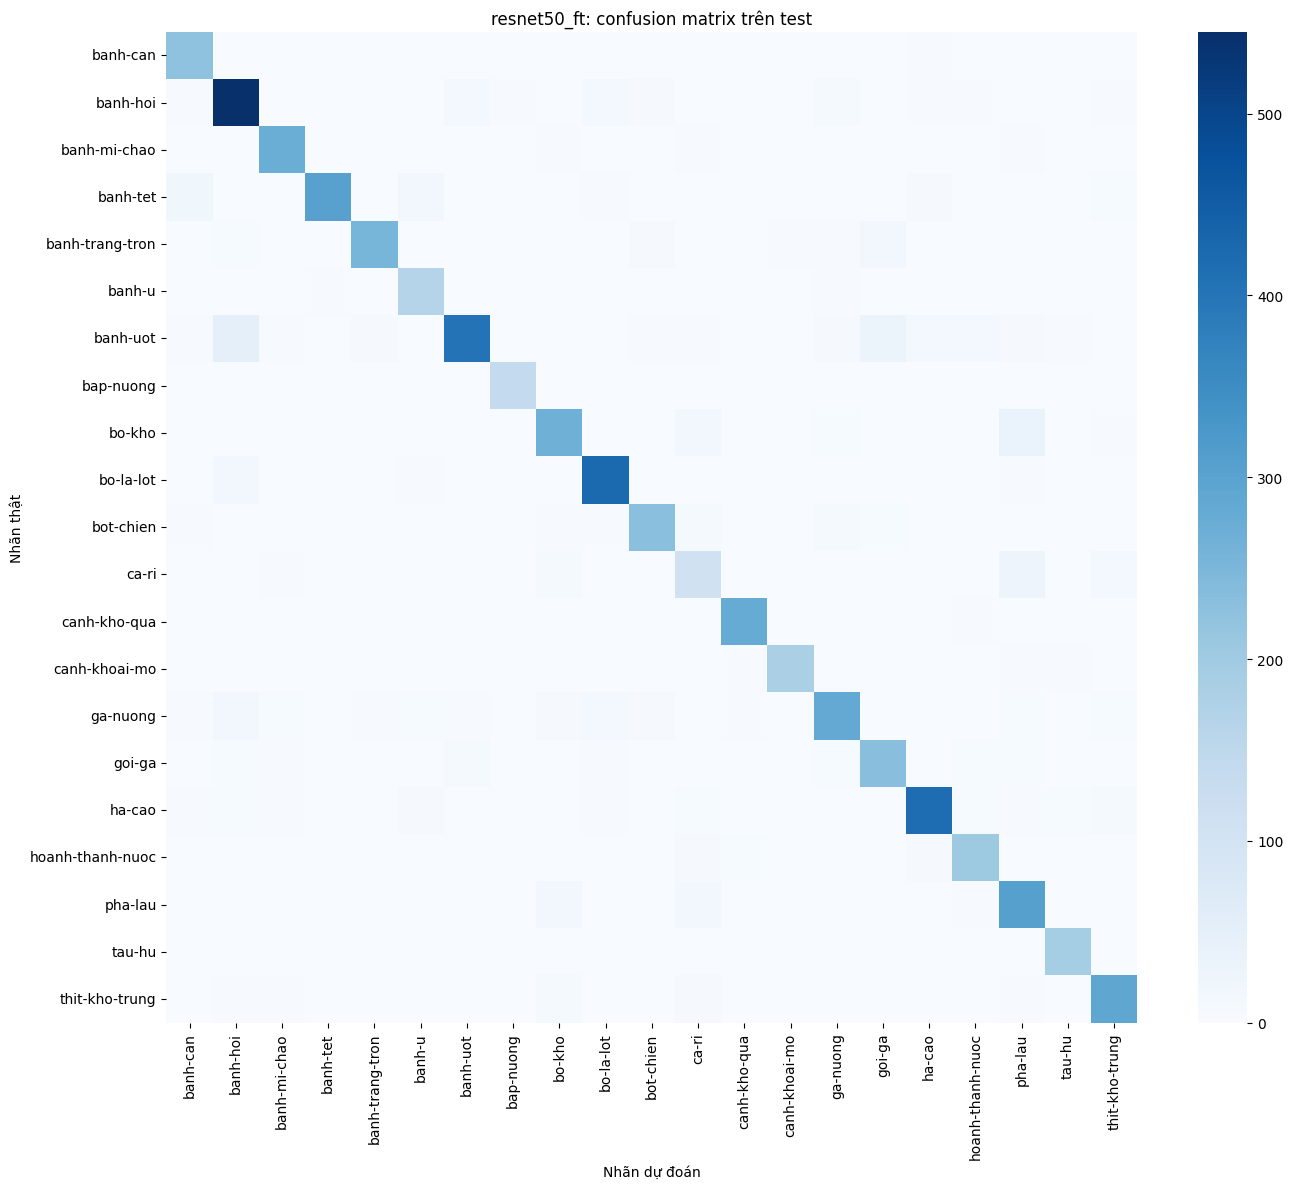

,accuracy,precision_macro,recall_macro,macro_f1,name,img_size,parameters,trainable_parameters,seconds_per_epoch,best_epoch,best_val_macro_f1,epochs,test_loss,n_train,n_val
0,0.8584,0.8576,0.8648,0.8591,resnet50_ft,224,23551061,23551061,137.8937,19,0.9044,20,0.5352,9040,1004


In [31]:
if RUN_EXPERIMENTS:
    RESULTS['resnet50_fe'] = run_experiment(
        'resnet50_fe', resnet50_feature_extraction, 224, True, 1e-3,
        EPOCHS_TRANSFER)
    RESULTS['resnet50_ft'] = run_experiment(
        'resnet50_ft', resnet50_finetune, 224, True, 1e-4,
        EPOCHS_TRANSFER)

## 9. Tổng hợp kết quả

In [32]:
EXPECTED_RUNS = ['lenet_avg', 'lenet_max', 'googlenet', 'resnet18_noaug',
                 'resnet18_aug', 'resnet50_fe', 'resnet50_ft']
if RESULTS:
    columns = ['name', 'img_size', 'parameters', 'trainable_parameters',
               'seconds_per_epoch', 'accuracy', 'precision_macro',
               'recall_macro', 'macro_f1', 'best_epoch', 'epochs']
    all_results = pd.DataFrame([RESULTS[k] for k in EXPECTED_RUNS if k in RESULTS])
    print('Tất cả thí nghiệm:')
    display(all_results[columns].round(4))
    all_results.to_csv(OUT_ROOT / 'comparison_all_runs.csv', index=False)

    groups = [['lenet_avg', 'lenet_max'], ['googlenet'],
              ['resnet18_noaug', 'resnet18_aug'], ['resnet50_fe', 'resnet50_ft']]
    selected = []
    for group in groups:
        available = [RESULTS[k] for k in group if k in RESULTS]
        if available:
            selected.append(max(available, key=lambda x: x['best_val_macro_f1']))
    print('Một biến thể của mỗi mô hình (chọn bằng validation):')
    display(pd.DataFrame(selected)[columns].round(4))
    pd.DataFrame(selected).to_csv(OUT_ROOT / 'comparison_four_models.csv',
                                  index=False)

    for first, second, title in [
        ('lenet_avg', 'lenet_max', 'LeNet MaxPool - AvgPool'),
        ('resnet18_noaug', 'resnet18_aug', 'ResNet18 có - không augment'),
        ('resnet50_fe', 'resnet50_ft', 'ResNet50 fine-tune - feature extraction'),
    ]:
        if first in RESULTS and second in RESULTS:
            diff = RESULTS[second]['macro_f1'] - RESULTS[first]['macro_f1']
            print(f'{title}: chênh macro-F1 = {diff:+.4f}')
    missing = [k for k in EXPECTED_RUNS if k not in RESULTS]
    print('Thí nghiệm còn thiếu:', missing if missing else 'không có')
else:
    print('Chưa huấn luyện; chưa có số liệu test để tổng hợp.')

Tất cả thí nghiệm:


,name,img_size,parameters,trainable_parameters,seconds_per_epoch,accuracy,precision_macro,recall_macro,macro_f1,best_epoch,epochs
0,lenet_avg,64,339421,339421,116.1329,0.3060,0.3064,0.2926,0.2883,19,20
1,lenet_max,64,339421,339421,101.3819,0.3304,0.3259,0.3172,0.3137,19,20
2,googlenet,64,120425,120425,101.9458,0.3831,0.3917,0.3661,0.3561,19,20
3,resnet18_noaug,96,11187285,11187285,90.9962,0.4249,0.4208,0.4110,0.4092,19,20
4,resnet18_aug,96,11187285,11187285,109.0984,0.5079,0.5088,0.4948,0.4951,19,20
5,resnet50_fe,224,23551061,43029,127.8485,0.7528,0.7656,0.7607,0.7608,19,20
6,resnet50_ft,224,23551061,23551061,137.8937,0.8584,0.8576,0.8648,0.8591,19,20


Một biến thể của mỗi mô hình (chọn bằng validation):


,name,img_size,parameters,trainable_parameters,seconds_per_epoch,accuracy,precision_macro,recall_macro,macro_f1,best_epoch,epochs
0,lenet_max,64,339421,339421,101.3819,0.3304,0.3259,0.3172,0.3137,19,20
1,googlenet,64,120425,120425,101.9458,0.3831,0.3917,0.3661,0.3561,19,20
2,resnet18_aug,96,11187285,11187285,109.0984,0.5079,0.5088,0.4948,0.4951,19,20
3,resnet50_ft,224,23551061,23551061,137.8937,0.8584,0.8576,0.8648,0.8591,19,20


LeNet MaxPool - AvgPool: chênh macro-F1 = +0.0254
ResNet18 có - không augment: chênh macro-F1 = +0.0859
ResNet50 fine-tune - feature extraction: chênh macro-F1 = +0.0983
Thí nghiệm còn thiếu: không có


## 10. Nhận xét kết quả và kết luận

### 10.1. Bài 1 — LeNet-5: AvgPool và MaxPool

LeNet dùng AvgPool đạt accuracy **30,60%** và F1-macro **28,83%**; thay bằng MaxPool
đạt accuracy **33,04%** và F1-macro **31,37%**. Như vậy, MaxPool tăng **2,44% accuracy** và **2,54% F1-macro** trong lần chạy này. Hai bản
đều có **339421 tham số**, nên sự khác biệt không đến từ việc tăng số tham số.

F1 từng lớp không tăng đồng đều: MaxPool cải thiện 16/21 lớp, trong đó `banh-tet`
tăng từ 0,2250 lên 0,3389, nhưng một số lớp như `banh-can` và `goi-ga` giảm nhẹ.
Vì vậy, có thể chọn MaxPool làm biến thể đại diện của LeNet trong thí nghiệm này,
nhưng chưa thể kết luận MaxPool luôn tốt hơn AvgPool trên mọi lần chạy.

### 10.2. Bài 2 — GoogLeNet rút gọn

Mạng có ba Inception block với số channel đầu ra lần lượt **56, 112 và 224**,
khớp giữa cách tính tổng channel bốn nhánh và shape in từ code. GoogLeNet đạt
accuracy **38,31%** và F1-macro **35,61%**, cao hơn LeNet MaxPool **4,24 điểm phần
trăm F1-macro**. Tổng số tham số là **120.425**, ít hơn LeNet khoảng **64,5%**.
Kết quả cho thấy cấu trúc nhiều nhánh kết hợp global average pooling đạt hiệu quả
tham số tốt hơn LeNet trong cấu hình đã thử.

Thời gian trung bình khoảng **101,95 giây/epoch**, gần bằng LeNet MaxPool
(**101,38 giây/epoch**). Do đó, ít tham số hơn không đồng nghĩa huấn luyện nhanh
hơn; thời gian còn phụ thuộc các phép tích chập ở từng nhánh, kích thước feature
map và việc đọc, biến đổi ảnh. Validation loss nhìn chung vẫn giảm đến gần cuối
20 epoch, nên chưa có bằng chứng mạng đã hội tụ hoàn toàn.

### 10.3. Bài 3 — ResNet-18 và tác động của augmentation

ResNet-18 không augmentation đạt accuracy **42,49%**, F1-macro **40,92%**. Khi có
augmentation, hai chỉ số tăng lên **50,79%** và **49,51%**. Mức tăng tương ứng là
**8,30% accuracy** và **8,59% F1-macro**. Cả hai bản
có **11187285 tham số** và cùng dùng ảnh 96×96.

Với không augmentation có dấu hiệu **overfitting từ khoảng epoch 8–10**:
validation loss thấp nhất ở epoch 7 là 1,8028, sau đó tăng lên 3,0418 ở epoch 20,
trong khi train loss tiếp tục giảm từ 1,4224 xuống 0,0639. Ở epoch 20, train
accuracy đạt 97,84% nhưng validation accuracy chỉ 47,01%. Mạng học rất tốt tập
train nhưng khả năng tổng quát hoá còn hạn chế.

Với có augmentation có validation loss giảm từ 2,5019 xuống mức thấp nhất 1,3738
ở epoch 19. Ở epoch 20, train loss và validation loss lần lượt là 1,0653 và
1,4399, với khoảng cách nhỏ hơn nhiều so với bản không augmentation. Augmentation
cải thiện F1 ở **19/21 lớp**; riêng `bot-chien` tăng từ 0,2487 lên 0,4783. Đây là
bằng chứng thực nghiệm cho thấy augmentation giúp hạn chế overfitting trong lần
chạy này, dù không bảo đảm cải thiện ở mọi lớp.

### 10.4. Bài 4 — ResNet-50 pretrained: feature extraction và fine-tuning

Feature extraction chỉ học **43029 tham số classifier**, trong tổng số
23551061 tham số của mạng, nhưng đã đạt accuracy **75,28%** và F1-macro
**76,08%**. Khi fine-tuning toàn bộ mạng, accuracy tăng lên **85,84%**,
precision-macro **85,76%**, recall-macro **86,48%** và F1-macro **85,91%**.
Fine-tuning tăng **9,83% F1-macro** so với feature extraction,
và cải thiện F1 ở **20/21 lớp**.

ResNet-50 fine-tuning có F1-macro cao hơn ResNet-18 có augmentation **36,40%**. Kết quả phù hợp với lợi ích của việc tận dụng đặc trưng pretrained
rồi thích nghi với VinaFood21. Tuy nhiên, so sánh này đồng thời khác kiến trúc,
kích thước ảnh (224×224 so với 96×96), số tham số và learning rate, nên không thể
quy toàn bộ chênh lệch cho riêng pretraining.

Ở cuối quá trình fine-tuning, train loss tiếp tục giảm đến 0,0729, còn validation
loss dao động quanh 0,35–0,38. Có khoảng cách train/validation, nhưng F1 validation
vẫn đạt cao nhất ở epoch 19; chưa thấy sự suy giảm kéo dài của F1 validation trong
20 epoch để kết luận overfitting nặng như ResNet-18 không augmentation.

### 10.5. Kết quả từng lớp và lỗi phân loại

Với mô hình tốt nhất, ResNet-50 fine-tuning, các lớp có F1 cao gồm `bap-nuong`
(**94,92%**), `canh-kho-qua` (**94,10%**), `canh-khoai-mo` (**94,03%**) và `tau-hu`
(**93,89%**). Lớp khó nhất là `ca-ri`, chỉ đạt **60,22% F1**, thấp hơn đáng kể so
với F1-macro chung. Các lớp `goi-ga` (**79,12%**), `ga-nuong` (**79,61%**) và
`bo-kho` (**79,76%**) cũng còn nhiều cải thiện.

Nhưng cần lưu ý confusion matrix đang dùng số ảnh tuyệt đối, trong khi số ảnh test mỗi lớp khác
nhau (từ 143 đến 607 ảnh). Vì vậy, không kết luận lớp có ô đường chéo đậm nhất là
lớp dễ nhất; cần đọc cùng recall và F1 từng lớp. Macro-F1 phù hợp để các lớp đều
có trọng số ngang nhau khi đánh giá.

### 10.6. Kết luận và giới hạn

Trong các cấu hình đã thử, **ResNet-50 fine-tuning cho kết quả tốt nhất** với
accuracy 85,84% và F1-macro 85,91%. LeNet MaxPool tốt hơn AvgPool trong lần chạy
này; GoogLeNet đạt F1 cao hơn LeNet với ít tham số hơn; augmentation cải thiện
ResNet-18 và làm giảm rõ khoảng cách train/val.

